In [1]:
import configparser
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
os.chdir('../')

In [2]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('../data.ini')
data = data['DEFAULT']

In [3]:
with open('../'+ data['hotnet2___all_noHypoHyper___out_dir'] + 'results/consensus/viz-data.json') as f:
    consensus_all = json.load(f)
with open('../'+ data['hotnet2___all_noHypoHyper_RAS___out_dir'] + 'results/consensus/viz-data.json') as f:
    consensus_RAS = json.load(f)
with open('../'+ data['hotnet2___all_noHypoHyper_nonRAS___out_dir'] + 'results/consensus/viz-data.json') as f:
    consensus_nonRAS = json.load(f)

In [4]:
def getSubnetworks(consensus):
    rows = []
    for subnetwork in consensus['subnetworks']['0']:
        heat = 0
        genes = []
        for node in subnetwork['nodes']:
            genes.append(node['name'])
            heat += node['value']
        rows.append({'genes': ', '.join(genes), 'size': len(genes), 'heat': heat})
    return pd.DataFrame(rows).sort_values('heat', ascending=False)

In [7]:
subnetworks_all = getSubnetworks(consensus_all)
subnetworks_RAS = getSubnetworks(consensus_RAS)
subnetworks_nonRAS = getSubnetworks(consensus_nonRAS)

In [8]:
numNetworks_heatGrater_all = pd.DataFrame(
    [(i, len(subnetworks_all.loc[subnetworks_all['heat'] >= i, 'genes'])) for i in subnetworks_all['heat'].unique()],
    columns=['heat', 'numNetworks']
)
numNetworks_heatGrater_RAS = pd.DataFrame(
    [(i, len(subnetworks_RAS.loc[subnetworks_RAS['heat'] >= i, 'genes'])) for i in subnetworks_RAS['heat'].unique()],
    columns=['heat', 'numNetworks']
)
numNetworks_heatGrater_nonRAS = pd.DataFrame(
    [(i, len(subnetworks_nonRAS.loc[subnetworks_nonRAS['heat'] >= i, 'genes'])) for i in subnetworks_nonRAS['heat'].unique()],
    columns=['heat', 'numNetworks']
)

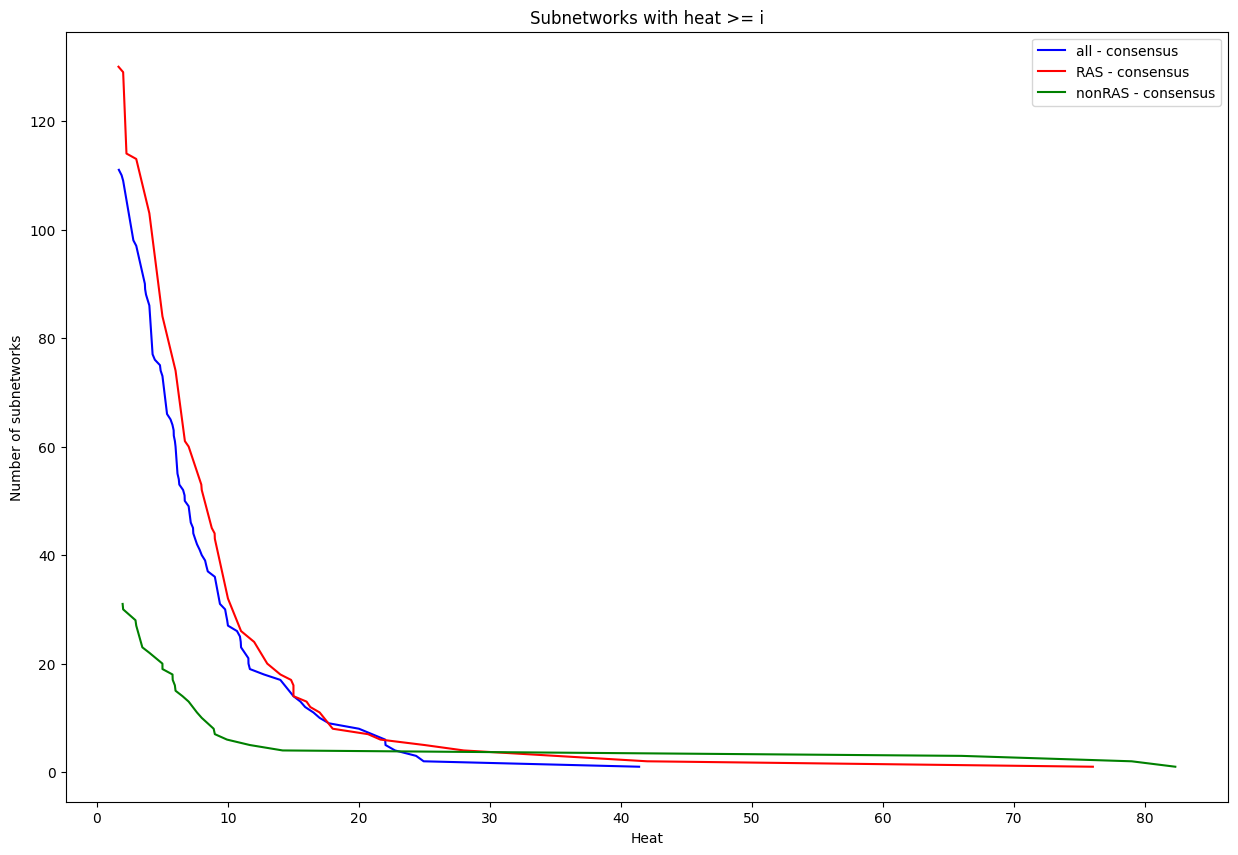

In [9]:
# plot
plt.figure(figsize=(15, 10))
plt.title('Subnetworks with heat >= i')
plt.plot(numNetworks_heatGrater_all.set_index('heat'), label='all - consensus', color='blue')
plt.plot(numNetworks_heatGrater_RAS.set_index('heat'), label='RAS - consensus', color='red')
plt.plot(numNetworks_heatGrater_nonRAS.set_index('heat'), label='nonRAS - consensus', color='green')
plt.xlabel('Heat')
plt.ylabel('Number of subnetworks')
plt.legend(loc='upper right', fontsize=10)
plt.savefig("../" + data['plots'] + 'hotnet2_cumulativeNumSignificantNetworks.png')
plt.show()

In [10]:
len(subnetworks_all), len(subnetworks_RAS), len(subnetworks_nonRAS)

(111, 130, 31)

In [16]:
len(genes_all), len(genes_RAS), len(genes_nonRAS)

(914, 1084, 400)

In [15]:
len(genes_onlyRAS), len(genes_onlyNonRAS), len(genes_onlyRAS_onlyNonRAS)

(865, 181, 1046)

In [11]:
# array with all genes in the subnetworks
genes_all = set()
for genes in subnetworks_all['genes']:
    genes_all.update(genes.split(', '))
genes_RAS = set()
for genes in subnetworks_RAS['genes']:
    genes_RAS.update(genes.split(', '))
genes_nonRAS = set()
for genes in subnetworks_nonRAS['genes']:
    genes_nonRAS.update(genes.split(', '))

In [12]:
len(genes_all), len(genes_RAS), len(genes_nonRAS)

(914, 1084, 400)

In [13]:
genes_onlyRAS = genes_RAS.difference(genes_nonRAS)
genes_onlyNonRAS = genes_nonRAS.difference(genes_RAS)
genes_onlyRAS_onlyNonRAS = set.union(genes_onlyRAS, genes_onlyNonRAS)

In [14]:
len(genes_onlyRAS), len(genes_onlyNonRAS), len(genes_onlyRAS_onlyNonRAS)

(865, 181, 1046)